In [2]:
import os
import re
import docx
import pdfplumber
import subprocess
import requests
from bs4 import BeautifulSoup
from typing import List
from typing_extensions import TypedDict, Dict, Any

from langsmith import traceable
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_core.prompts import ChatPromptTemplate

llm = ChatGroq(model="openai/gpt-oss-120b")

class ReWOO(TypedDict):
    task: str
    plan_string: str
    steps: List
    results: dict
    result: str

In [3]:
# Prompt instructing the LLM to generate a step-by-step plan using variables (#E1, #E2)
planner_prompt = """For the following task, make plans that can solve the problem step by step. For each plan, indicate \
which external tool together with tool input to retrieve evidence. You can store the evidence into a \
variable #E that can be called by later tools. (Plan, #E1, Plan, #E2, Plan, ...) Use the following format:
Plan: Explain the plan.
#E1 = TOOL[tool-input]

Plan: Explain the plan for the next step
#E2 = TOOL[tool-input]


Allowed TOOLs:
1) LLM[input]      - Let the language model reason
2) CV[input]       - The tool extract_cv_text, input = local path
3) JobPost[input]  - The tool job_posting_tool, input = a job-url

Do not invent any other tool names.
Begin!

Task: {task}
"""

# Define a sample task to test the planner's output format
task = """
look into my cv called cv-template.pdf can you evaluate it
and how would it perform on this posting: https://www.python.org/jobs/
"""

# Invoke the LLM to generate and print the structured plan
result = llm.invoke(planner_prompt.format(task=task))
print(result.content)

Plan: Extract the full text from your CV file so we have the content to analyse.  
#E1 = CV[cv-template.pdf]

Plan: Retrieve the current job postings from the Python.org jobs page to understand the required skills and qualifications.  
#E2 = JobPost[https://www.python.org/jobs/]

Plan: Use the language model to compare the extracted CV text (#E1) with the requirements and details of the job postings (#E2), and generate an evaluation of how well the CV matches the posting(s), including strengths, gaps, and suggestions for improvement.  
#E3 = LLM[Using the CV content:\n#E1\nand the job posting details:\n#E2\n, evaluate the CV’s relevance to the posting, highlight matching qualifications, identify missing or weak areas, and recommend enhancements to increase the CV’s effectiveness for this role.]


In [4]:
# Regular expression to parse each step into: (plan_description, variable_name, tool_name, tool_input)
plan_regex = r"Plan:\s*(.+?)\s*(#E\d+)\s*=\s*(\w+)\[(.+?)\]"

@traceable(name="Planner Node")
def planner_node(state: ReWOO):
    # Extract the user task from the current graph state
    task = state["task"]
    
    # Invoke the LLM to generate the raw step-by-step plan
    raw_plan = llm.invoke(planner_prompt.format(task=task)).content
    
    # Parse the raw plan into a structured list of tuples using regex
    steps = re.findall(plan_regex, raw_plan, flags=re.S)
    
    # Update the state with the raw plan string and the parsed steps
    return {"plan_string": raw_plan, "steps": steps}

In [5]:
@tool
def extract_cv_text(file_path: str) -> str:
    """Extracts the text content from a CV file in PDF, DOCX, or DOC format."""
    ext = os.path.splitext(file_path)[-1].lower()
    
    if ".docx" in ext:
        try:
            doc = docx.Document(file_path)
            return '\n'.join([para.text for para in doc.paragraphs])
        except Exception as e:
            return f"Error reading .docx file: {e}"
            
    elif ".pdf" in ext:
        try:
            text = []
            with pdfplumber.open(file_path) as pdf:
                for page in pdf.pages:
                    page_text = page.extract_text()
                    if page_text:
                        text.append(page_text)
            return '\n'.join(text)
        except Exception as e:
            return f"Error reading .pdf file: {e}"
            
    elif ".doc" in ext:
        try:
            subprocess.run(['soffice', '--headless', '--convert-to', 'docx', '--outdir', os.path.dirname(file_path), file_path], check=True)
            doc = docx.Document(os.path.splitext(file_path)[0] + ".docx")
            text = [para.text for para in doc.paragraphs]
            os.remove(os.path.splitext(file_path)[0] + ".docx")
            return '\n'.join(text)
        except Exception as e:
            return f"Error reading .doc file: {e}"
            
    return "Unsupported file format! Please use .pdf, .docx, or .doc."

@tool
@traceable(name="Job Posting Tool")
def job_posting_tool(job_link: str) -> str:
    """Visits the provided job posting link, reads its contents, and summarizes key details."""
    try:
        headers = {"User-Agent": "Mozilla/5.0"}
        response = requests.get(job_link, headers=headers, timeout=10)
        soup = BeautifulSoup(response.text, "html.parser")
        page_content = soup.get_text(separator="\n", strip=True)[:8000]
    except Exception as e:
        return f"Job posting unavailable or contains no job details. Error: {e}"

    system_prompt = """You are a helpful tool that reads job postings and summarizes key details (title, company, location, salary, required skills, responsibilities) in a clear bullet-point list."""
    messages = [
        ("system", system_prompt),
        ("user", f"Summarize this job posting:\nLink: {job_link}\n\nContent:\n{page_content}")
    ]
    return llm.invoke(messages).content

# Store tools in a list
tools = [job_posting_tool, extract_cv_text]

In [6]:
# Determine the index of the next step to execute based on collected results
def _current_index(state: ReWOO):
    done = len(state.get("results", {}))
    total = len(state["steps"])
    return None if done >= total else done

In [7]:
@traceable(name="Executor Node")
def executor_node(state: ReWOO):
    # Find the index of the next unexecuted step
    idx = _current_index(state)
    if idx is None:
        return {}
        
    # Unpack the current step details
    _, step_name, tool_name, tool_input = state["steps"][idx]
    
    # Replace any variable placeholders (#E1, #E2, etc.) with their actual collected results
    for k, v in state.get("results", {}).items():
        tool_input = tool_input.replace(k, v)
        
    # Execute the corresponding tool based on tool_name
    if tool_name == "LLM":
        out = llm.invoke(tool_input).content
    elif tool_name == "CV":
        out = extract_cv_text.invoke(tool_input)
    elif tool_name == "JobPost":
        out = job_posting_tool.invoke(tool_input)
    else:
        raise ValueError(f"Unknown tool {tool_name}")
        
    # Save the tool output into the results dictionary
    results = dict(state.get("results", {}))
    results[step_name] = str(out)
    return {"results": results}

In [8]:
# Prompt instructing the LLM to synthesize the final answer using the plan and collected evidence
solver_prompt = """Solve the following task or problem. To solve the problem, we have made step-by-step Plan and retrieved corresponding Evidence to each Plan. Use them with caution since long evidence might contain irrelevant information.

{plan_block}

Now solve the question or task according to provided Evidence above. Respond with the answer directly with no extra words.

Task: {task}
Response:
"""

@traceable(name="Solver Node")
def solver_node(state: ReWOO):
    # Combine each plan step with its corresponding evidence from the results dictionary
    lines = []
    for plan_text, step_name, tool_name, tool_input in state["steps"]:
        evidence = state["results"][step_name]
        lines.append(f"Plan: {plan_text}\nEvidence {step_name}: {evidence}\n")
        
    # Format the final prompt and invoke the LLM
    prompt = solver_prompt.format(plan_block="\n".join(lines), task=state["task"])
    answer = llm.invoke(prompt).content.strip()
    
    # Return the final synthesized answer
    return {"result": answer}

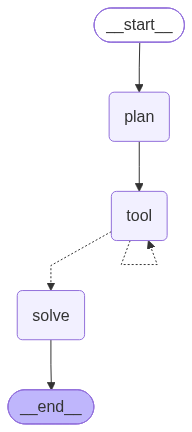

In [11]:
from langgraph.graph import START, StateGraph, END
from IPython.display import Image, display

# Conditional router: move to 'solve' if all plan steps are executed, otherwise loop back to 'tool'
def router(state: ReWOO):
    return "solve" if _current_index(state) is None else "tool"

# Initialize the StateGraph with the ReWOO state schema
builder = StateGraph(ReWOO)

# Add the three specialized nodes
builder.add_node("plan", planner_node)
builder.add_node("tool", executor_node)
builder.add_node("solve", solver_node)

# Define the execution flow and edges
builder.set_entry_point("plan")
builder.add_edge("plan", "tool")
builder.add_conditional_edges("tool", router, {"tool": "tool", "solve": "solve"})
builder.add_edge("solve", END)

# Compile the graph and visualize its architecture
rewoo_graph = builder.compile()
display(Image(rewoo_graph.get_graph().draw_mermaid_png()))

In [12]:
# Define the user request containing the CV path and target job postings
user_request = (
    "I stored my CV at 'cv-template.pdf'. "
    "Here are the job details:\n"
    "1) https://www.python.org/jobs/\n"
    "Which role is the best fit for me and why (short)?"
)

# Initialize the starting ReWOO state
state: ReWOO = {
    "task": user_request,
    "plan_string": "",
    "steps": [],
    "results": {},
    "result": ""
}

# Stream and print the output of each node as it executes
final_state = None
for event in rewoo_graph.stream(state):
    print(event)
    print("---")
    for node_output in event.values():
        if "result" in node_output:
            final_state = node_output["result"]

print("\nFINAL ANSWER:\n", final_state)

{'plan': {'plan_string': 'Plan: Extract the text from your CV file so we can analyze your skills, experience, and qualifications.  \n#E1 = CV[cv-template.pdf]\n\nPlan: Retrieve the current list of job postings from the Python.org jobs page to see which roles are available.  \n#E2 = JobPost[https://www.python.org/jobs/]\n\nPlan: Use the language model to compare the extracted CV content (#E1) with each job description retrieved (#E2) and identify the role that best matches your background, providing a brief justification.  \n#E3 = LLM[Using CV text #E1 and job postings #E2, determine the best‑fit role and explain why (short).]', 'steps': [('Extract the text from your CV file so we can analyze your skills, experience, and qualifications.', '#E1', 'CV', 'cv-template.pdf'), ('Retrieve the current list of job postings from the Python.org jobs page to see which roles are available.', '#E2', 'JobPost', 'https://www.python.org/jobs/'), ('Use the language model to compare the extracted CV conte